In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


#**Dataset**


In [2]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/thesis_DR/"
    "aptos_exact_duplicate_audit.csv"
)

df = pd.read_csv(path)

keep = df[df["action"] == "KEEP"].copy()

assert len(keep) == 3504
assert keep["image_id"].nunique() == 3504

print("APTOS FINAL DATASET")
print("Total retained:", len(keep))

print("\nGRADE DISTRIBUTION")
for grade in range(5):
    n = int((keep["original_grade"] == grade).sum())
    print(f"Grade {grade}: {n} ({n/len(keep)*100:.2f}%)")

non_ref = int((keep["original_grade"] <= 1).sum())
ref = int((keep["original_grade"] >= 2).sum())

print("\nBINARY DISTRIBUTION")
print(f"Non-referable: {non_ref} ({non_ref/len(keep)*100:.2f}%)")
print(f"Referable: {ref} ({ref/len(keep)*100:.2f}%)")

print("\nEXCLUSION SUMMARY")
print(df["action"].value_counts().to_string())

APTOS FINAL DATASET
Total retained: 3504

GRADE DISTRIBUTION
Grade 0: 1796 (51.26%)
Grade 1: 338 (9.65%)
Grade 2: 922 (26.31%)
Grade 3: 177 (5.05%)
Grade 4: 271 (7.73%)

BINARY DISTRIBUTION
Non-referable: 2134 (60.90%)
Referable: 1370 (39.10%)

EXCLUSION SUMMARY
action
KEEP                      3504
DROP_EXACT_DUPLICATE        96
EXCLUDE_LABEL_CONFLICT      62


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Existing audit manifests found.
Upload your Kaggle API token: kaggle.json


Saving kaggle.json to kaggle.json
APTOS 2019: 3662 images available.


100%|██████████| 408M/408M [00:19<00:00, 21.7MB/s]

Extracting files...


IDRiD: 516 images available.


Downloading...
From (original): https://drive.google.com/uc?id=1vOLBUK9xdzNV8eVkRjVdNrRwhPfaOmda
From (redirected): https://drive.google.com/uc?id=1vOLBUK9xdzNV8eVkRjVdNrRwhPfaOmda&confirm=t&uuid=a29b0f39-6723-4a6d-af9d-4016c6cc207d
To: /content/MESSIDOR2.zip
100%|██████████| 2.51G/2.51G [00:53<00:00, 46.7MB/s]


Messidor-2 archive extracted.
APTOS retained cohort verified: 3504.
IDRiD retained cohort verified: 507.
Messidor-2 retained cohort verified: 1740.

Selected images:
   dataset  grade                                     image_id
APTOS 2019      0                                 18cde9649e90
APTOS 2019      1                                 bebb3f167654
APTOS 2019      2                                 a150ff5dfe07
APTOS 2019      3                                 6e92b1c5ac8e
APTOS 2019      4                                 6d259b5b4c76
     IDRiD      0                              train_IDRiD_342
     IDRiD      1                               test_IDRiD_073
     IDRiD      2                              train_IDRiD_236
     IDRiD      3                              train_IDRiD_001
     IDRiD      4                               test_IDRiD_032
Messidor-2      0       train/anodr/20060522_46149_0100_PP.png
Messidor-2      1                     val/bmilddr/IM000406.png
Messidor-2     

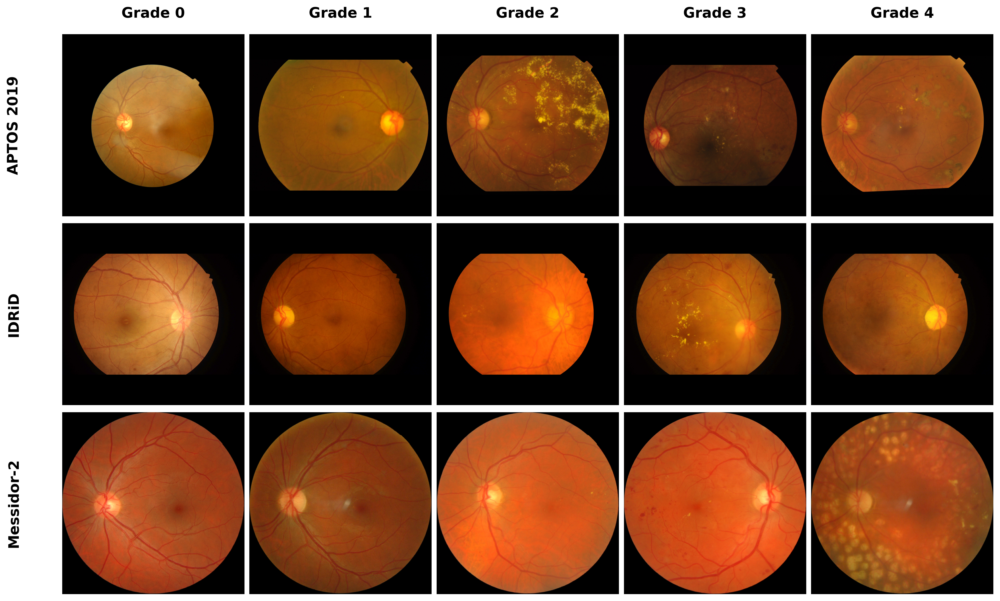


FIGURE 2 CREATED
Datasets: 3
DR grades: 5
Selected original images: 15
Layout: 3 rows × 5 columns

PNG: /content/DR_Figure_2/Fig_2_Retinal_Datasets_Grades.png
TIFF: /content/DR_Figure_2/Fig_2_Retinal_Datasets_Grades.tif
Manifest: /content/DR_Figure_2/Fig_2_Selected_Image_Manifest.csv

All figure files are temporary Colab outputs.
No original data or Drive audit files were modified.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# ============================================================
# FIG. 2 — REPRESENTATIVE FUNDUS IMAGES
# APTOS 2019 | IDRiD | Messidor-2
# 3 datasets × 5 DR severity grades
#
# - Download datasets to temporary Colab storage
# - Use the existing retained-image audit manifests
# - Select one verified image per dataset and grade
# - Preserve original image content and colors
# - Create publication-quality PNG and TIFF
# - Save exact image provenance for reproducibility
# - Do not modify research datasets or audit files
# ============================================================

import os
import sys
import shutil
import subprocess
import zipfile
import hashlib
from pathlib import Path

subprocess.run(
    [
        sys.executable, "-m", "pip", "install", "-q",
        "kaggle", "kagglehub", "gdown",
        "pandas", "numpy", "pillow", "matplotlib"
    ],
    check=True
)

import gdown
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from google.colab import drive, files

# ============================================================
# 1. GOOGLE DRIVE — EXISTING AUDIT MANIFESTS
# ============================================================

drive.mount("/content/drive")

PROJECT = Path("/content/drive/MyDrive/thesis_DR")

APTOS_AUDIT = PROJECT / "aptos_exact_duplicate_audit.csv"
IDRID_AUDIT = PROJECT / "idrid_exact_duplicate_audit.csv"

for path in [APTOS_AUDIT, IDRID_AUDIT]:
    if not path.is_file():
        raise FileNotFoundError(
            f"Required audit manifest not found: {path}"
        )

print("Existing audit manifests found.")

# ============================================================
# 2. DOWNLOAD APTOS 2019 TO TEMPORARY COLAB STORAGE
# ============================================================

APTOS_DIR = Path("/content/APTOS")
APTOS_IMAGES = APTOS_DIR / "train_images"

aptos_ready = (
    (APTOS_DIR / "train.csv").is_file()
    and len(list(APTOS_IMAGES.glob("*.png"))) == 3662
)

if not aptos_ready:

    kaggle_config = Path.home() / ".kaggle" / "kaggle.json"

    if (
        not kaggle_config.is_file()
        and not (
            os.getenv("KAGGLE_USERNAME")
            and os.getenv("KAGGLE_KEY")
        )
    ):

        if Path("/content/kaggle.json").is_file():
            source = Path("/content/kaggle.json")

        else:
            print("Upload your Kaggle API token: kaggle.json")

            uploaded = files.upload()

            if "kaggle.json" not in uploaded:
                raise RuntimeError(
                    "Kaggle API token was not provided."
                )

            source = Path("/content/kaggle.json")

        kaggle_config.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        shutil.copyfile(source, kaggle_config)
        kaggle_config.chmod(0o600)

    APTOS_DIR.mkdir(parents=True, exist_ok=True)

    aptos_zip = (
        APTOS_DIR / "aptos2019-blindness-detection.zip"
    )

    if not aptos_zip.is_file():

        subprocess.run(
            [
                "kaggle",
                "competitions",
                "download",
                "-c",
                "aptos2019-blindness-detection",
                "-p",
                str(APTOS_DIR)
            ],
            check=True
        )

    with zipfile.ZipFile(aptos_zip) as archive:

        base = APTOS_DIR.resolve()

        for member in archive.infolist():
            target = (base / member.filename).resolve()

            if not target.is_relative_to(base):
                raise RuntimeError(
                    "Unsafe file path in APTOS archive."
                )

        archive.extractall(APTOS_DIR)

assert len(list(APTOS_IMAGES.glob("*.png"))) == 3662, (
    "APTOS download is incomplete."
)

print("APTOS 2019: 3662 images available.")

# ============================================================
# 3. DOWNLOAD IDRiD TO TEMPORARY STORAGE
# SAME DATA SOURCE USED IN THE EXTERNAL NOTEBOOK
# ============================================================

IDRID_ROOT = Path(
    kagglehub.dataset_download(
        "dankok/diabetic-retinopathy-image-dataset"
    )
)

GRADING = IDRID_ROOT / "Disease_Grading"

if not GRADING.is_dir():
    raise FileNotFoundError(
        f"IDRiD Disease_Grading folder not found: {GRADING}"
    )

IDRID_MAPS = {}

for split, folder_name in [
    ("train", "Training Set"),
    ("test", "Testing Set")
]:

    image_dir = (
        GRADING / "Original_Images" / folder_name
    )

    if not image_dir.is_dir():
        raise FileNotFoundError(image_dir)

    IDRID_MAPS[split] = {
        p.stem.strip(): p
        for p in image_dir.iterdir()
        if p.is_file()
        and p.suffix.lower() in {
            ".jpg", ".jpeg", ".png"
        }
    }

assert len(IDRID_MAPS["train"]) == 413
assert len(IDRID_MAPS["test"]) == 103

print("IDRiD: 516 images available.")

# ============================================================
# 4. DOWNLOAD MESSIDOR-2
# EXACT RETFOUND BENCHMARK SOURCE FROM OUR NOTEBOOK
# ============================================================

MESSIDOR_ZIP = Path("/content/MESSIDOR2.zip")
MESSIDOR_DIR = Path("/content/MESSIDOR2")
MESSIDOR_ROOT = MESSIDOR_DIR / "MESSIDOR2"

FILE_ID = "1vOLBUK9xdzNV8eVkRjVdNrRwhPfaOmda"

if not MESSIDOR_ZIP.is_file():

    result = gdown.download(
        id=FILE_ID,
        output=str(MESSIDOR_ZIP),
        quiet=False
    )

    if not result or not MESSIDOR_ZIP.is_file():
        raise RuntimeError(
            "Messidor-2 download failed."
        )

if not MESSIDOR_ROOT.is_dir():

    MESSIDOR_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    with zipfile.ZipFile(MESSIDOR_ZIP) as archive:

        base = MESSIDOR_DIR.resolve()

        for member in archive.infolist():
            target = (base / member.filename).resolve()

            if not target.is_relative_to(base):
                raise RuntimeError(
                    "Unsafe file path in Messidor-2 archive."
                )

        archive.extractall(MESSIDOR_DIR)

assert MESSIDOR_ROOT.is_dir(), (
    "Messidor-2 extraction failed."
)

print("Messidor-2 archive extracted.")

# ============================================================
# 5. HASH FUNCTION — VERIFY EXACT SOURCE IMAGES
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()

# ============================================================
# 6. LOAD THE RETAINED APTOS COHORT
# ============================================================

aptos_audit = pd.read_csv(
    APTOS_AUDIT,
    dtype={"image_id": str}
)

required = {
    "image_id",
    "original_grade",
    "action",
    "sha256"
}

assert required.issubset(aptos_audit.columns)

aptos_keep = aptos_audit[
    aptos_audit["action"] == "KEEP"
].copy()

assert len(aptos_keep) == 3504

expected_aptos = [1796, 338, 922, 177, 271]

actual_aptos = (
    aptos_keep["original_grade"]
    .value_counts()
    .reindex(range(5), fill_value=0)
    .tolist()
)

assert actual_aptos == expected_aptos, (
    "APTOS retained-grade distribution does not match."
)

aptos_rows = []

for rec in aptos_keep.itertuples(index=False):

    image_path = (
        APTOS_IMAGES / f"{rec.image_id}.png"
    )

    if not image_path.is_file():
        raise FileNotFoundError(image_path)

    aptos_rows.append({
        "dataset": "APTOS 2019",
        "grade": int(rec.original_grade),
        "image_id": str(rec.image_id),
        "path": str(image_path),
        "sha256": str(rec.sha256)
    })

print("APTOS retained cohort verified: 3504.")

# ============================================================
# 7. LOAD THE RETAINED IDRiD COHORT
# ============================================================

idrid_audit = pd.read_csv(
    IDRID_AUDIT,
    dtype={"original_image_id": str}
)

required = {
    "original_image_id",
    "original_grade",
    "source_split",
    "audit_status",
    "sha256"
}

assert required.issubset(idrid_audit.columns)

idrid_keep = idrid_audit[
    idrid_audit["audit_status"] == "KEEP"
].copy()

assert len(idrid_keep) == 507

expected_idrid = [167, 23, 165, 91, 61]

actual_idrid = (
    idrid_keep["original_grade"]
    .value_counts()
    .reindex(range(5), fill_value=0)
    .tolist()
)

assert actual_idrid == expected_idrid, (
    "IDRiD retained-grade distribution does not match."
)

idrid_rows = []

for rec in idrid_keep.itertuples(index=False):

    split = str(rec.source_split).lower()
    image_id = str(rec.original_image_id).strip()

    image_path = IDRID_MAPS[split].get(image_id)

    if image_path is None:
        raise FileNotFoundError(
            f"Missing IDRiD image: {split}/{image_id}"
        )

    idrid_rows.append({
        "dataset": "IDRiD",
        "grade": int(rec.original_grade),
        "image_id": f"{split}_{image_id}",
        "path": str(image_path),
        "sha256": str(rec.sha256)
    })

print("IDRiD retained cohort verified: 507.")

# ============================================================
# 8. RECONSTRUCT MESSIDOR-2 RETAINED COHORT
# SAME CLASS MAPPING AND DUPLICATE RULE AS OUR NOTEBOOK
# ============================================================

CLASS_TO_GRADE = {
    "anodr": 0,
    "bmilddr": 1,
    "cmoderatedr": 2,
    "dseveredr": 3,
    "eproliferativedr": 4
}

image_exts = {
    ".jpg", ".jpeg", ".png", ".tif", ".tiff"
}

messidor_paths = sorted([
    p for p in MESSIDOR_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in image_exts
])

assert len(messidor_paths) == 1744, (
    f"Expected 1744 Messidor-2 images, "
    f"found {len(messidor_paths)}."
)

messidor_rows = []

for image_path in messidor_paths:

    class_name = image_path.parent.name
    split_name = image_path.parent.parent.name

    assert class_name in CLASS_TO_GRADE
    assert split_name in {"train", "val", "test"}

    messidor_rows.append({
        "dataset": "Messidor-2",
        "grade": CLASS_TO_GRADE[class_name],
        "image_id": str(
            image_path.relative_to(MESSIDOR_ROOT)
        ),
        "path": str(image_path),
        "sha256": sha256_file(image_path)
    })

messidor_all = pd.DataFrame(
    messidor_rows
).sort_values(
    ["sha256", "path"]
).reset_index(drop=True)

# Check that exact duplicates have consistent labels.

grade_consistency = (
    messidor_all.groupby("sha256")["grade"].nunique()
)

assert (grade_consistency == 1).all(), (
    "Conflicting-grade Messidor-2 duplicates detected."
)

# Retain one image per SHA-256 group.

messidor_keep = messidor_all.drop_duplicates(
    subset="sha256",
    keep="first"
).copy()

assert len(messidor_keep) == 1740

expected_messidor = [1017, 268, 345, 75, 35]

actual_messidor = (
    messidor_keep["grade"]
    .value_counts()
    .reindex(range(5), fill_value=0)
    .tolist()
)

assert actual_messidor == expected_messidor, (
    "Messidor-2 retained-grade distribution does not match."
)

print("Messidor-2 retained cohort verified: 1740.")

# ============================================================
# 9. COMBINE VERIFIED RETAINED COHORTS
# ============================================================

cohorts = pd.concat(
    [
        pd.DataFrame(aptos_rows),
        pd.DataFrame(idrid_rows),
        messidor_keep
    ],
    ignore_index=True
)

assert len(cohorts) == 3504 + 507 + 1740

DATASETS = [
    "APTOS 2019",
    "IDRiD",
    "Messidor-2"
]

# ============================================================
# 10. DETERMINISTIC IMAGE SELECTION
# ONE REAL IMAGE PER DATASET AND SEVERITY GRADE
# ============================================================

SEED = 42

rng = np.random.default_rng(SEED)

selected = []

for dataset in DATASETS:

    for grade in range(5):

        options = cohorts[
            (cohorts["dataset"] == dataset)
            & (cohorts["grade"] == grade)
        ].sort_values(
            "image_id"
        ).reset_index(drop=True)

        assert len(options) > 0

        index = int(
            rng.integers(0, len(options))
        )

        sample = options.iloc[index].to_dict()

        # Verify that selected file matches its audit record.

        actual_hash = sha256_file(
            Path(sample["path"])
        )

        assert actual_hash == sample["sha256"], (
            f"Image hash mismatch: {sample['image_id']}"
        )

        selected.append(sample)

selection = pd.DataFrame(selected)

assert len(selection) == 15

print("\nSelected images:")
print(
    selection[
        ["dataset", "grade", "image_id"]
    ].to_string(index=False)
)

# ============================================================
# 11. CREATE JOURNAL FIGURE
#
# Rows: APTOS 2019, IDRiD, Messidor-2
# Columns: Grade 0, Grade 1, Grade 2, Grade 3, Grade 4
#
# No cropping, lesion annotations, enhancement,
# artificial images, or unnecessary text.
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 13,
    "figure.facecolor": "white",
    "savefig.facecolor": "white"
})

fig, axes = plt.subplots(
    3,
    5,
    figsize=(15, 9.1),
    dpi=300
)

fig.patch.set_facecolor("white")

fig.subplots_adjust(
    left=0.092,
    right=0.995,
    bottom=0.018,
    top=0.912,
    wspace=0.018,
    hspace=0.038
)

# ------------------------------------------------------------
# DRAW FUNDUS IMAGES
# ------------------------------------------------------------

for row, dataset in enumerate(DATASETS):

    for grade in range(5):

        ax = axes[row, grade]

        record = selection[
            (selection["dataset"] == dataset)
            & (selection["grade"] == grade)
        ].iloc[0]

        image_path = Path(record["path"])

        with Image.open(image_path) as img:

            img = ImageOps.exif_transpose(img)

            img = img.convert("RGB")

            # Preserve the complete retinal image.
            # Add padding only; do not crop or stretch.

            tile = ImageOps.pad(
                img,
                size=(700, 700),
                method=Image.Resampling.LANCZOS,
                color=(0, 0, 0),
                centering=(0.5, 0.5)
            )

        ax.imshow(tile)
        ax.set_axis_off()

# ------------------------------------------------------------
# COLUMN LABELS — GRADES ONLY
# ------------------------------------------------------------

for grade in range(5):

    position = axes[0, grade].get_position()

    center_x = (
        position.x0 + position.width / 2
    )

    fig.text(
        center_x,
        0.945,
        f"Grade {grade}",
        ha="center",
        va="center",
        fontsize=15,
        fontweight="semibold"
    )

# ------------------------------------------------------------
# ROW LABELS — DATASET NAMES ONLY
# ------------------------------------------------------------

for row, dataset in enumerate(DATASETS):

    position = axes[row, 0].get_position()

    center_y = (
        position.y0 + position.height / 2
    )

    fig.text(
        0.046,
        center_y,
        dataset,
        ha="center",
        va="center",
        rotation=90,
        fontsize=15,
        fontweight="semibold"
    )

# ============================================================
# 12. SAVE PUBLICATION-QUALITY FIGURE
# ============================================================

OUTPUT_DIR = Path("/content/DR_Figure_2")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PNG_PATH = (
    OUTPUT_DIR / "Fig_2_Retinal_Datasets_Grades.png"
)

TIFF_PATH = (
    OUTPUT_DIR / "Fig_2_Retinal_Datasets_Grades.tif"
)

MANIFEST_PATH = (
    OUTPUT_DIR / "Fig_2_Selected_Image_Manifest.csv"
)

fig.savefig(
    PNG_PATH,
    dpi=300,
    facecolor="white"
)

plt.show()
plt.close(fig)

# TIFF with lossless compression and 300-DPI metadata.

with Image.open(PNG_PATH) as img:

    img.save(
        TIFF_PATH,
        format="TIFF",
        compression="tiff_lzw",
        dpi=(300, 300)
    )

# Save source image IDs, verified grades, and hashes.

selection[
    [
        "dataset",
        "grade",
        "image_id",
        "sha256",
        "path"
    ]
].to_csv(
    MANIFEST_PATH,
    index=False
)

# ============================================================
# 13. PACKAGE OUTPUTS FOR DOWNLOAD
# ============================================================

ZIP_OUTPUT = (
    Path("/content") / "DR_Figure_2_Package.zip"
)

with zipfile.ZipFile(
    ZIP_OUTPUT,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:

    for path in [
        PNG_PATH,
        TIFF_PATH,
        MANIFEST_PATH
    ]:

        z.write(
            path,
            arcname=path.name
        )

print("\n" + "=" * 60)
print("FIGURE 2 CREATED")
print("=" * 60)

print("Datasets:", len(DATASETS))
print("DR grades:", 5)
print("Selected original images:", len(selection))
print("Layout: 3 rows × 5 columns")

print("\nPNG:", PNG_PATH)
print("TIFF:", TIFF_PATH)
print("Manifest:", MANIFEST_PATH)

print("\nAll figure files are temporary Colab outputs.")
print("No original data or Drive audit files were modified.")

files.download(str(ZIP_OUTPUT))

#**Classification Results**

In [ ]:
# ============================================================
# APTOS CLASSIFICATION RESULTS
# DISPLAY ONLY - NOTHING SAVED
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.special import expit

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    balanced_accuracy_score
)

# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_DR")

PRED_PATH = PROJECT_DIR / "aptos_retfound_raw_predictions.csv"
TEMP_PATH = PROJECT_DIR / "aptos_retfound_temperature_scaling.json"

SEEDS = [42, 43, 44, 45, 46]


# ============================================================
# LOAD
# ============================================================

pred = pd.read_csv(PRED_PATH)

with open(TEMP_PATH, "r") as f:
    temp_data = json.load(f)


# ============================================================
# CALCULATE METRICS
# ============================================================

rows = []

for seed in SEEDS:

    test = pred[
        (pred["seed"] == seed) &
        (pred["split"] == "internal_test")
    ].copy()

    assert len(test) == 526

    y = test["binary_label"].to_numpy(dtype=int)
    logits = test["raw_logit"].to_numpy(dtype=float)

    # Frozen temperature
    T = float(
        temp_data["seeds"][str(seed)]["temperature"]
    )

    prob = expit(logits / T)

    # Standard classification threshold
    y_pred = (prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y,
        y_pred,
        labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    ppv = (
        tp / (tp + fp)
        if (tp + fp) > 0 else np.nan
    )

    npv = (
        tn / (tn + fn)
        if (tn + fn) > 0 else np.nan
    )

    rows.append({
        "Seed": seed,
        "AUROC": roc_auc_score(y, prob),
        "AUPRC": average_precision_score(y, prob),
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "PPV": ppv,
        "NPV": npv,
        "F1-score": f1_score(y, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y,
            y_pred
        )
    })


results = pd.DataFrame(rows)


# ============================================================
# NICE RESULT TABLE
# ============================================================

metrics = [
    "AUROC",
    "AUPRC",
    "Sensitivity",
    "Specificity",
    "PPV",
    "NPV",
    "F1-score",
    "Balanced Accuracy"
]

table = pd.DataFrame({
    "Metric": metrics
})

for seed in SEEDS:
    seed_row = results[
        results["Seed"] == seed
    ].iloc[0]

    table[f"Seed {seed}"] = [
        seed_row[m] for m in metrics
    ]


table["Mean ± SD"] = [
    f"{results[m].mean():.4f} ± {results[m].std(ddof=1):.4f}"
    for m in metrics
]


# Format seed columns
for col in [
    f"Seed {s}" for s in SEEDS
]:
    table[col] = table[col].map(
        lambda x: f"{x:.4f}"
    )


# ============================================================
# DISPLAY
# ============================================================

print("\n========== APTOS CLASSIFICATION RESULTS ==========\n")
print("Untouched internal-test evaluation")
print("Classification threshold = 0.5")
print("5 repeated source splits\n")

display(
    table.style
    .set_caption(
        "Classification Performance Across Five Seeds"
    )
    .set_properties(
        **{
            "text-align": "center"
        }
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("font-weight", "bold")
            ]
        }
    ])
)

print("\nMAIN RESULTS")
print(
    f"AUROC             : "
    f"{results['AUROC'].mean():.4f} ± "
    f"{results['AUROC'].std(ddof=1):.4f}"
)

print(
    f"AUPRC             : "
    f"{results['AUPRC'].mean():.4f} ± "
    f"{results['AUPRC'].std(ddof=1):.4f}"
)

print(
    f"Sensitivity       : "
    f"{results['Sensitivity'].mean():.4f} ± "
    f"{results['Sensitivity'].std(ddof=1):.4f}"
)

print(
    f"Specificity       : "
    f"{results['Specificity'].mean():.4f} ± "
    f"{results['Specificity'].std(ddof=1):.4f}"
)

print(
    f"Balanced Accuracy : "
    f"{results['Balanced Accuracy'].mean():.4f} ± "
    f"{results['Balanced Accuracy'].std(ddof=1):.4f}"
)

print("\nDISPLAY ONLY - NO FILE SAVED.")


========== APTOS CLASSIFICATION RESULTS ==========

Untouched internal-test evaluation
Classification threshold = 0.5
5 repeated source splits



,Metric,Seed 42,Seed 43,Seed 44,Seed 45,Seed 46,Mean ± SD
0,AUROC,0.9820,0.9778,0.9785,0.9809,0.9809,0.9800 ± 0.0018
1,AUPRC,0.9707,0.9581,0.9633,0.9628,0.9690,0.9648 ± 0.0051
2,Sensitivity,0.9610,0.8976,0.9220,0.8932,0.9320,0.9211 ± 0.0276
3,Specificity,0.9034,0.9470,0.9128,0.9437,0.9313,0.9276 ± 0.0191
4,PPV,0.8640,0.9154,0.8710,0.9109,0.8972,0.8917 ± 0.0232
5,NPV,0.9732,0.9354,0.9482,0.9321,0.9551,0.9488 ± 0.0165
6,F1-score,0.9099,0.9064,0.8957,0.9020,0.9143,0.9057 ± 0.0072
7,Balanced Accuracy,0.9322,0.9223,0.9174,0.9185,0.9316,0.9244 ± 0.0071



MAIN RESULTS
AUROC             : 0.9800 ± 0.0018
AUPRC             : 0.9648 ± 0.0051
Sensitivity       : 0.9211 ± 0.0276
Specificity       : 0.9276 ± 0.0191
Balanced Accuracy : 0.9244 ± 0.0071

DISPLAY ONLY - NO FILE SAVED.


Classification main metric: AUROC
Whole-paper main metric: Auto-clear risk at useful coverage, with 95% upper risk bound

#**APTOS ROC Curve**

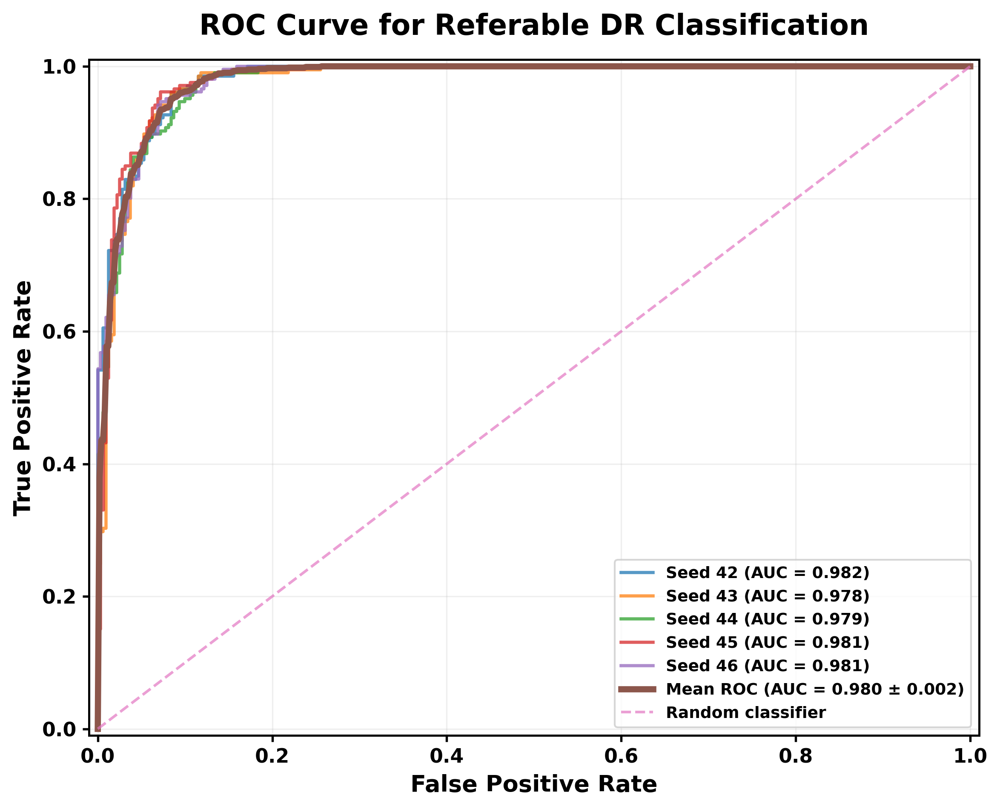


Mean AUROC = 0.9800 ± 0.0018
DISPLAY ONLY - NO FILE SAVED.


In [ ]:
# ============================================================
# APTOS ROC CURVE
# HIGH-QUALITY DISPLAY ONLY
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.special import expit
from sklearn.metrics import roc_curve, roc_auc_score


# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_DR")

PRED_PATH = PROJECT_DIR / "aptos_retfound_raw_predictions.csv"
TEMP_PATH = PROJECT_DIR / "aptos_retfound_temperature_scaling.json"

SEEDS = [42, 43, 44, 45, 46]


# ============================================================
# LOAD
# ============================================================

pred = pd.read_csv(PRED_PATH)

with open(TEMP_PATH, "r") as f:
    temp_data = json.load(f)


# ============================================================
# PLOT SETTINGS
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold"
})

fig, ax = plt.subplots(
    figsize=(8, 6.5),
    dpi=300
)

mean_fpr = np.linspace(0, 1, 500)

all_tpr = []
all_auc = []


# ============================================================
# ROC FOR EACH SEED
# ============================================================

for seed in SEEDS:

    test = pred[
        (pred["seed"] == seed) &
        (pred["split"] == "internal_test")
    ].copy()

    y = test[
        "binary_label"
    ].to_numpy(dtype=int)

    logits = test[
        "raw_logit"
    ].to_numpy(dtype=float)

    T = float(
        temp_data["seeds"][str(seed)]["temperature"]
    )

    probabilities = expit(
        logits / T
    )

    fpr, tpr, _ = roc_curve(
        y,
        probabilities
    )

    seed_auc = roc_auc_score(
        y,
        probabilities
    )

    all_auc.append(seed_auc)

    interpolated_tpr = np.interp(
        mean_fpr,
        fpr,
        tpr
    )

    interpolated_tpr[0] = 0.0

    all_tpr.append(
        interpolated_tpr
    )

    ax.plot(
        fpr,
        tpr,
        linewidth=1.8,
        alpha=0.75,
        label=f"Seed {seed} (AUC = {seed_auc:.3f})"
    )


# ============================================================
# MEAN ROC
# ============================================================

mean_tpr = np.mean(
    all_tpr,
    axis=0
)

mean_tpr[-1] = 1.0

mean_auc = np.mean(all_auc)
std_auc = np.std(all_auc, ddof=1)

ax.plot(
    mean_fpr,
    mean_tpr,
    linewidth=3.5,
    label=(
        f"Mean ROC "
        f"(AUC = {mean_auc:.3f} ± {std_auc:.3f})"
    )
)


# ============================================================
# RANDOM CLASSIFIER
# ============================================================

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    alpha=0.7,
    label="Random classifier"
)


# ============================================================
# FORMATTING
# ============================================================

ax.set_title(
    "ROC Curve for Referable DR Classification",
    fontsize=16,
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "False Positive Rate",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel(
    "True Positive Rate",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)

ax.tick_params(
    axis="both",
    labelsize=11,
    width=1.3
)

for label in (
    ax.get_xticklabels()
    + ax.get_yticklabels()
):
    label.set_fontweight("bold")


ax.legend(
    loc="lower right",
    fontsize=9,
    frameon=True
)

ax.grid(
    alpha=0.20,
    linewidth=0.8
)

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()


print(
    f"\nMean AUROC = "
    f"{mean_auc:.4f} ± {std_auc:.4f}"
)

print("DISPLAY ONLY - NO FILE SAVED.")

#**Precision–Recall Curve (PR Curve)**

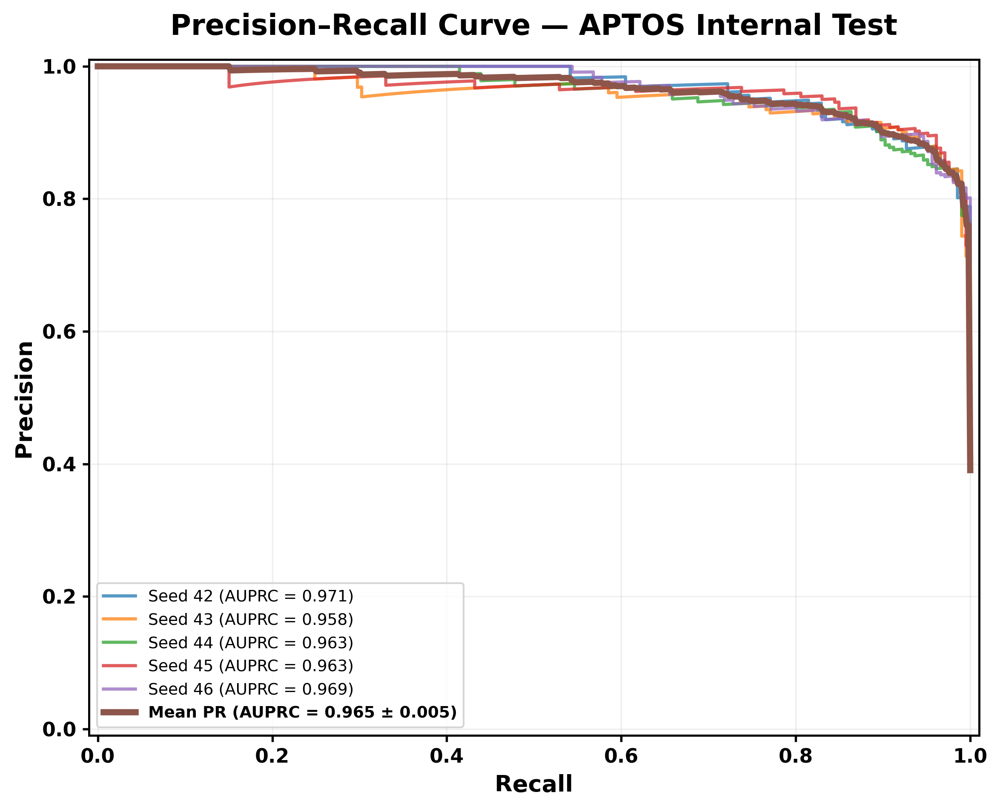


Mean AUPRC = 0.9648 ± 0.0051
DISPLAY ONLY - NO FILE SAVED.


In [ ]:
# ============================================================
# APTOS PRECISION-RECALL CURVE
# HIGH-QUALITY DISPLAY ONLY
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.special import expit
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_DR")

PRED_PATH = PROJECT_DIR / "aptos_retfound_raw_predictions.csv"
TEMP_PATH = PROJECT_DIR / "aptos_retfound_temperature_scaling.json"

SEEDS = [42, 43, 44, 45, 46]

# ============================================================
# LOAD
# ============================================================

pred = pd.read_csv(PRED_PATH)

with open(TEMP_PATH, "r") as f:
    temp_data = json.load(f)

# ============================================================
# PLOT SETTINGS
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold"
})

fig, ax = plt.subplots(
    figsize=(8, 6.5),
    dpi=300
)

mean_recall = np.linspace(0, 1, 500)

all_precision = []
all_auprc = []

# ============================================================
# PR CURVE FOR EACH SEED
# ============================================================

for seed in SEEDS:

    test = pred[
        (pred["seed"] == seed) &
        (pred["split"] == "internal_test")
    ].copy()

    y = test["binary_label"].to_numpy(dtype=int)
    logits = test["raw_logit"].to_numpy(dtype=float)

    T = float(
        temp_data["seeds"][str(seed)]["temperature"]
    )

    probabilities = expit(
        logits / T
    )

    precision, recall, _ = precision_recall_curve(
        y,
        probabilities
    )

    auprc = average_precision_score(
        y,
        probabilities
    )

    all_auprc.append(auprc)

    ax.plot(
        recall,
        precision,
        linewidth=1.8,
        alpha=0.75,
        label=f"Seed {seed} (AUPRC = {auprc:.3f})"
    )

    # sklearn recall is descending, so reverse for interpolation
    interp_precision = np.interp(
        mean_recall,
        recall[::-1],
        precision[::-1]
    )

    all_precision.append(
        interp_precision
    )

# ============================================================
# MEAN PR CURVE
# ============================================================

mean_precision = np.mean(
    all_precision,
    axis=0
)

mean_auprc = np.mean(all_auprc)
std_auprc = np.std(all_auprc, ddof=1)

ax.plot(
    mean_recall,
    mean_precision,
    linewidth=3.5,
    label=(
        f"Mean PR "
        f"(AUPRC = {mean_auprc:.3f} ± {std_auprc:.3f})"
    )
)

# ============================================================
# FORMAT
# ============================================================

ax.set_title(
    "Precision–Recall Curve — APTOS Internal Test",
    fontsize=16,
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "Recall",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel(
    "Precision",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)

ax.tick_params(
    axis="both",
    labelsize=11,
    width=1.3
)

for label in (
    ax.get_xticklabels()
    + ax.get_yticklabels()
):
    label.set_fontweight("bold")

# ============================================================
# LEGEND
# Seed entries normal
# Mean PR entry bold
# ============================================================

legend = ax.legend(
    loc="lower left",
    fontsize=9,
    frameon=True
)

for text in legend.get_texts():
    text.set_fontweight("normal")

legend.get_texts()[-1].set_fontweight("bold")

# ============================================================
# GRID / BORDER
# ============================================================

ax.grid(
    alpha=0.20,
    linewidth=0.8
)

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

# ============================================================
# MAIN RESULT
# ============================================================

print(
    f"\nMean AUPRC = "
    f"{mean_auprc:.4f} ± {std_auprc:.4f}"
)

print("DISPLAY ONLY - NO FILE SAVED.")

#**APTOS Calibration Results**

In [ ]:
# ============================================================
# APTOS CALIBRATION RESULTS
# DISPLAY ONLY - NOTHING SAVED
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.special import expit

from sklearn.metrics import (
    log_loss,
    brier_score_loss
)

# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_DR")

PRED_PATH = PROJECT_DIR / "aptos_retfound_raw_predictions.csv"
TEMP_PATH = PROJECT_DIR / "aptos_retfound_temperature_scaling.json"

SEEDS = [42, 43, 44, 45, 46]
ECE_BINS = 10

# ============================================================
# LOAD
# ============================================================

pred = pd.read_csv(PRED_PATH)

with open(TEMP_PATH, "r") as f:
    temp_data = json.load(f)

# ============================================================
# ECE
# ============================================================

def calculate_ece(probs, labels, n_bins=10):

    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (probs >= bins[i]) &
                (probs <= bins[i + 1])
            )
        else:
            mask = (
                (probs >= bins[i]) &
                (probs < bins[i + 1])
            )

        if mask.sum() == 0:
            continue

        mean_confidence = probs[mask].mean()
        observed_rate = labels[mask].mean()

        ece += (
            mask.mean()
            * abs(mean_confidence - observed_rate)
        )

    return float(ece)

# ============================================================
# CALCULATE
# ============================================================

rows = []

for seed in SEEDS:

    test = pred[
        (pred["seed"] == seed) &
        (pred["split"] == "internal_test")
    ].copy()

    y = test["binary_label"].to_numpy(dtype=int)
    logits = test["raw_logit"].to_numpy(dtype=float)

    T = float(
        temp_data["seeds"][str(seed)]["temperature"]
    )

    raw_prob = expit(logits)
    calibrated_prob = expit(logits / T)

    rows.append({
        "Seed": seed,

        "Raw NLL":
            log_loss(y, raw_prob, labels=[0, 1]),

        "Calibrated NLL":
            log_loss(y, calibrated_prob, labels=[0, 1]),

        "Raw Brier":
            brier_score_loss(y, raw_prob),

        "Calibrated Brier":
            brier_score_loss(y, calibrated_prob),

        "Raw ECE":
            calculate_ece(raw_prob, y, ECE_BINS),

        "Calibrated ECE":
            calculate_ece(
                calibrated_prob,
                y,
                ECE_BINS
            )
    })

results = pd.DataFrame(rows)

# ============================================================
# SUMMARY TABLE
# ============================================================

summary = pd.DataFrame({

    "Metric": [
        "NLL",
        "Brier Score",
        "ECE"
    ],

    "Before Temperature Scaling": [
        f"{results['Raw NLL'].mean():.4f} ± "
        f"{results['Raw NLL'].std(ddof=1):.4f}",

        f"{results['Raw Brier'].mean():.4f} ± "
        f"{results['Raw Brier'].std(ddof=1):.4f}",

        f"{results['Raw ECE'].mean():.4f} ± "
        f"{results['Raw ECE'].std(ddof=1):.4f}"
    ],

    "After Temperature Scaling": [
        f"{results['Calibrated NLL'].mean():.4f} ± "
        f"{results['Calibrated NLL'].std(ddof=1):.4f}",

        f"{results['Calibrated Brier'].mean():.4f} ± "
        f"{results['Calibrated Brier'].std(ddof=1):.4f}",

        f"{results['Calibrated ECE'].mean():.4f} ± "
        f"{results['Calibrated ECE'].std(ddof=1):.4f}"
    ]
})

# ============================================================
# DISPLAY
# ============================================================

print(
    "\n========== APTOS CALIBRATION RESULTS ==========\n"
)

display(
    summary.style
    .set_caption(
        "Calibration Before and After Temperature Scaling"
    )
    .set_properties(
        **{"text-align": "center"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("font-weight", "bold")
            ]
        }
    ])
)

print("\nDISPLAY ONLY - NO FILE SAVED.")


========== APTOS CALIBRATION RESULTS ==========



,Metric,Before Temperature Scaling,After Temperature Scaling
0,NLL,0.1781 ± 0.0067,0.1768 ± 0.0071
1,Brier Score,0.0543 ± 0.0018,0.0539 ± 0.0016
2,ECE,0.0309 ± 0.0088,0.0293 ± 0.0074



DISPLAY ONLY - NO FILE SAVED.


#**Reliability Diagram.**

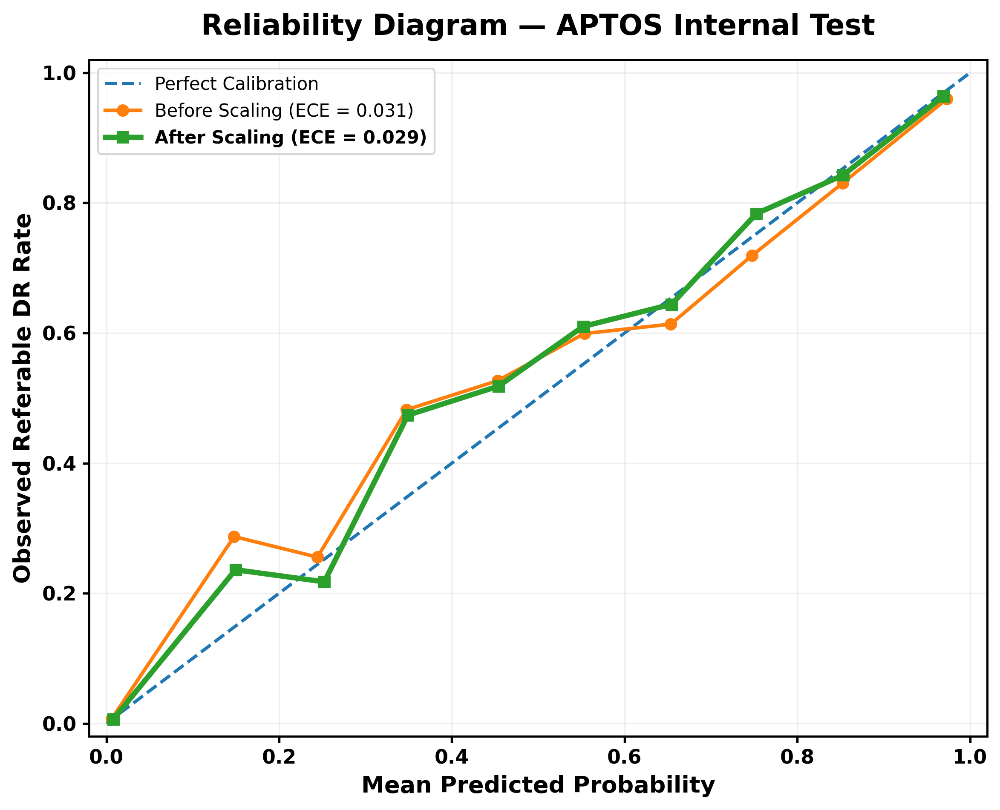


Mean ECE before scaling : 0.0309
Mean ECE after scaling  : 0.0293

DISPLAY ONLY - NO FILE SAVED.


In [ ]:
# ============================================================
# APTOS RELIABILITY DIAGRAM
# HIGH-QUALITY DISPLAY ONLY
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.special import expit

# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_DR")

PRED_PATH = PROJECT_DIR / "aptos_retfound_raw_predictions.csv"
TEMP_PATH = PROJECT_DIR / "aptos_retfound_temperature_scaling.json"

SEEDS = [42, 43, 44, 45, 46]
N_BINS = 10

# ============================================================
# LOAD
# ============================================================

pred = pd.read_csv(PRED_PATH)

with open(TEMP_PATH, "r") as f:
    temp_data = json.load(f)

# ============================================================
# RELIABILITY + ECE FUNCTION
# ============================================================

def reliability_stats(probs, labels, n_bins=10):

    bins = np.linspace(0, 1, n_bins + 1)

    mean_confidence = np.full(n_bins, np.nan)
    observed_rate = np.full(n_bins, np.nan)

    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (probs >= bins[i]) &
                (probs <= bins[i + 1])
            )
        else:
            mask = (
                (probs >= bins[i]) &
                (probs < bins[i + 1])
            )

        if mask.sum() == 0:
            continue

        mean_confidence[i] = probs[mask].mean()
        observed_rate[i] = labels[mask].mean()

        ece += (
            mask.mean()
            * abs(mean_confidence[i] - observed_rate[i])
        )

    return mean_confidence, observed_rate, float(ece)

# ============================================================
# COLLECT ALL 5 SEEDS
# ============================================================

raw_conf_all = []
raw_obs_all = []

cal_conf_all = []
cal_obs_all = []

raw_ece_all = []
cal_ece_all = []

for seed in SEEDS:

    test = pred[
        (pred["seed"] == seed) &
        (pred["split"] == "internal_test")
    ].copy()

    y = test["binary_label"].to_numpy(dtype=int)
    logits = test["raw_logit"].to_numpy(dtype=float)

    T = float(
        temp_data["seeds"][str(seed)]["temperature"]
    )

    raw_prob = expit(logits)
    cal_prob = expit(logits / T)

    # Before calibration
    raw_conf, raw_obs, raw_ece = reliability_stats(
        raw_prob,
        y,
        N_BINS
    )

    # After calibration
    cal_conf, cal_obs, cal_ece = reliability_stats(
        cal_prob,
        y,
        N_BINS
    )

    raw_conf_all.append(raw_conf)
    raw_obs_all.append(raw_obs)

    cal_conf_all.append(cal_conf)
    cal_obs_all.append(cal_obs)

    raw_ece_all.append(raw_ece)
    cal_ece_all.append(cal_ece)

# ============================================================
# MEAN ACROSS SEEDS
# ============================================================

raw_conf_mean = np.nanmean(
    np.array(raw_conf_all),
    axis=0
)

raw_obs_mean = np.nanmean(
    np.array(raw_obs_all),
    axis=0
)

cal_conf_mean = np.nanmean(
    np.array(cal_conf_all),
    axis=0
)

cal_obs_mean = np.nanmean(
    np.array(cal_obs_all),
    axis=0
)

mean_raw_ece = np.mean(raw_ece_all)
mean_cal_ece = np.mean(cal_ece_all)

# Remove bins empty across all seeds
raw_valid = (
    ~np.isnan(raw_conf_mean) &
    ~np.isnan(raw_obs_mean)
)

cal_valid = (
    ~np.isnan(cal_conf_mean) &
    ~np.isnan(cal_obs_mean)
)

# ============================================================
# PLOT
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold"
})

fig, ax = plt.subplots(
    figsize=(8, 6.5),
    dpi=300
)

# Perfect calibration line
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.8,
    label="Perfect Calibration"
)

# Before temperature scaling
ax.plot(
    raw_conf_mean[raw_valid],
    raw_obs_mean[raw_valid],
    marker="o",
    markersize=6,
    linewidth=2.0,
    label=f"Before Scaling (ECE = {mean_raw_ece:.3f})"
)

# After temperature scaling
ax.plot(
    cal_conf_mean[cal_valid],
    cal_obs_mean[cal_valid],
    marker="s",
    markersize=6,
    linewidth=3.0,
    label=f"After Scaling (ECE = {mean_cal_ece:.3f})"
)

# ============================================================
# FORMAT
# ============================================================

ax.set_title(
    "Reliability Diagram — APTOS Internal Test",
    fontsize=16,
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "Mean Predicted Probability",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel(
    "Observed Referable DR Rate",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)

ax.tick_params(
    axis="both",
    labelsize=11,
    width=1.3
)

for label in (
    ax.get_xticklabels()
    + ax.get_yticklabels()
):
    label.set_fontweight("bold")

# ============================================================
# LEGEND
# Only AFTER SCALING bold
# ============================================================

legend = ax.legend(
    loc="upper left",
    fontsize=10,
    frameon=True
)

for text in legend.get_texts():
    text.set_fontweight("normal")

legend.get_texts()[-1].set_fontweight("bold")

ax.grid(
    alpha=0.20,
    linewidth=0.8
)

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

# ============================================================
# RESULT
# ============================================================

print(
    f"\nMean ECE before scaling : {mean_raw_ece:.4f}"
)

print(
    f"Mean ECE after scaling  : {mean_cal_ece:.4f}"
)

print("\nDISPLAY ONLY - NO FILE SAVED.")

#**Selective Risk-Control Results**

In [ ]:
# ============================================================
# APTOS SELECTIVE RISK-CONTROL RESULTS
# DISPLAY ONLY - NOTHING SAVED
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.special import expit
from scipy.stats import beta


# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_DR")

PRED_PATH = PROJECT_DIR / "aptos_retfound_raw_predictions.csv"
TEMP_PATH = PROJECT_DIR / "aptos_retfound_temperature_scaling.json"
LTT_PATH = PROJECT_DIR / "aptos_retfound_ltt_risk_control.csv"

SEEDS = [42, 43, 44, 45, 46]
ALPHA = 0.05


# ============================================================
# LOAD
# ============================================================

pred = pd.read_csv(PRED_PATH)
ltt = pd.read_csv(LTT_PATH)

with open(TEMP_PATH, "r") as f:
    temp_data = json.load(f)


# ============================================================
# 95% ONE-SIDED EXACT UPPER BOUND
# ============================================================

def upper_risk_bound(errors, n):

    if n == 0:
        return np.nan

    if errors == n:
        return 1.0

    return float(
        beta.ppf(
            0.95,
            errors + 1,
            n - errors
        )
    )


# ============================================================
# EVALUATE FROZEN POLICY
# ============================================================

rows = []

for seed in SEEDS:

    test = pred[
        (pred["seed"] == seed) &
        (pred["split"] == "internal_test")
    ].copy()

    assert len(test) == 526

    y = test["binary_label"].to_numpy(dtype=int)
    logits = test["raw_logit"].to_numpy(dtype=float)

    # Frozen temperature
    T = float(
        temp_data["seeds"][str(seed)]["temperature"]
    )

    prob = expit(logits / T)

    # Frozen 5% LTT threshold
    policy = ltt[
        (ltt["seed"] == seed) &
        np.isclose(ltt["alpha"], ALPHA)
    ]

    assert len(policy) == 1

    threshold = float(
        policy.iloc[0]["selected_threshold"]
    )

    # Auto-clear decision
    auto_clear = prob <= threshold

    total = len(y)

    auto_clear_count = int(
        auto_clear.sum()
    )

    errors = int(
        (
            auto_clear &
            (y == 1)
        ).sum()
    )

    referable_total = int(
        (y == 1).sum()
    )

    coverage = auto_clear_count / total

    review_burden = 1 - coverage

    risk = (
        errors / auto_clear_count
        if auto_clear_count > 0
        else np.nan
    )

    npv = 1 - risk

    miss_proportion = (
        errors / referable_total
        if referable_total > 0
        else np.nan
    )

    upper = upper_risk_bound(
        errors,
        auto_clear_count
    )

    rows.append({
        "Seed": seed,
        "Threshold": threshold,
        "Auto-clear": auto_clear_count,
        "Referable Errors": errors,
        "Coverage": coverage,
        "Review Burden": review_burden,
        "Auto-clear Risk": risk,
        "Auto-clear NPV": npv,
        "Referable Miss": miss_proportion,
        "95% Upper Risk Bound": upper,
        "5% Target Met": upper <= ALPHA
    })


results = pd.DataFrame(rows)


# ============================================================
# DISPLAY TABLE
# ============================================================

display_table = results.copy()

for col in [
    "Threshold",
    "Coverage",
    "Review Burden",
    "Auto-clear Risk",
    "Auto-clear NPV",
    "Referable Miss",
    "95% Upper Risk Bound"
]:
    display_table[col] = display_table[col].map(
        lambda x: f"{x:.4f}"
    )

display_table["5% Target Met"] = display_table[
    "5% Target Met"
].map(
    lambda x: "YES" if x else "NO"
)


print(
    "\n========== APTOS SELECTIVE RISK-CONTROL RESULTS ==========\n"
)

display(
    display_table.style
    .set_caption(
        "Frozen 5% LTT Policy on the Untouched Internal Test"
    )
    .set_properties(
        **{"text-align": "center"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("font-weight", "bold")
            ]
        }
    ])
)


# ============================================================
# MAIN SUMMARY
# ============================================================

print("\n========== MAIN RESULT ==========\n")

print(
    f"Mean Coverage           : "
    f"{results['Coverage'].mean():.4f} ± "
    f"{results['Coverage'].std(ddof=1):.4f}"
)

print(
    f"Mean Review Burden      : "
    f"{results['Review Burden'].mean():.4f} ± "
    f"{results['Review Burden'].std(ddof=1):.4f}"
)

print(
    f"Mean Auto-clear Risk    : "
    f"{results['Auto-clear Risk'].mean():.4f} ± "
    f"{results['Auto-clear Risk'].std(ddof=1):.4f}"
)

print(
    f"Mean Auto-clear NPV     : "
    f"{results['Auto-clear NPV'].mean():.4f} ± "
    f"{results['Auto-clear NPV'].std(ddof=1):.4f}"
)

print(
    f"Mean 95% Upper Bound    : "
    f"{results['95% Upper Risk Bound'].mean():.4f} ± "
    f"{results['95% Upper Risk Bound'].std(ddof=1):.4f}"
)

print(
    f"5% Target Satisfied     : "
    f"{results['5% Target Met'].sum()} / 5 seeds"
)

print("\nDISPLAY ONLY - NO FILE SAVED.")


========== APTOS SELECTIVE RISK-CONTROL RESULTS ==========



,Seed,Threshold,Auto-clear,Referable Errors,Coverage,Review Burden,Auto-clear Risk,Auto-clear NPV,Referable Miss,95% Upper Risk Bound,5% Target Met
0,42,0.1593,270,1,0.5133,0.4867,0.0037,0.9963,0.0049,0.0174,YES
1,43,0.0280,272,2,0.5171,0.4829,0.0074,0.9926,0.0098,0.0230,YES
2,44,0.0463,255,0,0.4848,0.5152,0.0000,1.0000,0.0000,0.0117,YES
3,45,0.0747,278,2,0.5285,0.4715,0.0072,0.9928,0.0097,0.0225,YES
4,46,0.0972,268,0,0.5095,0.4905,0.0000,1.0000,0.0000,0.0111,YES



========== MAIN RESULT ==========

Mean Coverage           : 0.5106 ± 0.0161
Mean Review Burden      : 0.4894 ± 0.0161
Mean Auto-clear Risk    : 0.0037 ± 0.0036
Mean Auto-clear NPV     : 0.9963 ± 0.0036
Mean 95% Upper Bound    : 0.0171 ± 0.0057
5% Target Satisfied     : 5 / 5 seeds

DISPLAY ONLY - NO FILE SAVED.


#**Risk–Coverage Curve.**

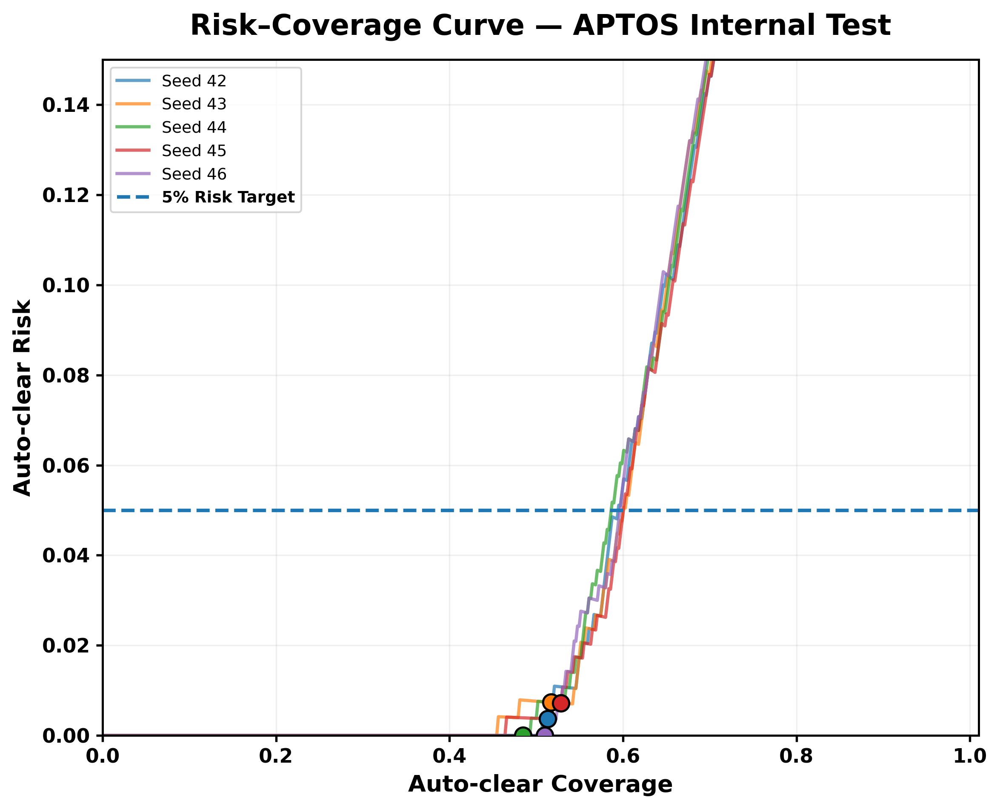


========== FROZEN 5% LTT OPERATING POINTS ==========

Seed 42: Coverage = 0.5133, Risk = 0.0037
Seed 43: Coverage = 0.5171, Risk = 0.0074
Seed 44: Coverage = 0.4848, Risk = 0.0000
Seed 45: Coverage = 0.5285, Risk = 0.0072
Seed 46: Coverage = 0.5095, Risk = 0.0000

Mean Coverage = 0.5106
Mean Risk = 0.0037

DISPLAY ONLY - NO FILE SAVED.


In [ ]:
# ============================================================
# APTOS RISK-COVERAGE CURVE
# DISPLAY ONLY - NOTHING SAVED
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.special import expit


# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_DR")

PRED_PATH = PROJECT_DIR / "aptos_retfound_raw_predictions.csv"
TEMP_PATH = PROJECT_DIR / "aptos_retfound_temperature_scaling.json"
LTT_PATH = PROJECT_DIR / "aptos_retfound_ltt_risk_control.csv"

SEEDS = [42, 43, 44, 45, 46]
ALPHA = 0.05


# ============================================================
# LOAD
# ============================================================

pred = pd.read_csv(PRED_PATH)
ltt = pd.read_csv(LTT_PATH)

with open(TEMP_PATH, "r") as f:
    temp_data = json.load(f)


# ============================================================
# PLOT SETTINGS
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.labelweight": "bold",
    "axes.titleweight": "bold"
})

fig, ax = plt.subplots(
    figsize=(8, 6.5),
    dpi=300
)

frozen_points_x = []
frozen_points_y = []


# ============================================================
# EACH SEED
# ============================================================

for seed in SEEDS:

    test = pred[
        (pred["seed"] == seed) &
        (pred["split"] == "internal_test")
    ].copy()

    y = test["binary_label"].to_numpy(dtype=int)
    logits = test["raw_logit"].to_numpy(dtype=float)

    # Frozen temperature
    T = float(
        temp_data["seeds"][str(seed)]["temperature"]
    )

    prob = expit(logits / T)


    # ========================================================
    # DESCRIPTIVE RISK-COVERAGE CURVE
    # Threshold sweep is ONLY for visualization
    # ========================================================

    thresholds = np.sort(
        np.unique(prob)
    )

    coverage_values = []
    risk_values = []

    for threshold in thresholds:

        auto_clear = prob <= threshold

        n_clear = int(
            auto_clear.sum()
        )

        if n_clear == 0:
            continue

        errors = int(
            (
                auto_clear &
                (y == 1)
            ).sum()
        )

        coverage = n_clear / len(y)
        risk = errors / n_clear

        coverage_values.append(coverage)
        risk_values.append(risk)


    ax.plot(
        coverage_values,
        risk_values,
        linewidth=1.8,
        alpha=0.70,
        label=f"Seed {seed}"
    )


    # ========================================================
    # FROZEN LTT OPERATING POINT
    # ========================================================

    policy = ltt[
        (ltt["seed"] == seed) &
        np.isclose(
            ltt["alpha"],
            ALPHA
        )
    ].iloc[0]

    frozen_threshold = float(
        policy["selected_threshold"]
    )

    frozen_auto = (
        prob <= frozen_threshold
    )

    frozen_count = int(
        frozen_auto.sum()
    )

    frozen_errors = int(
        (
            frozen_auto &
            (y == 1)
        ).sum()
    )

    frozen_coverage = (
        frozen_count / len(y)
    )

    frozen_risk = (
        frozen_errors / frozen_count
        if frozen_count > 0
        else np.nan
    )

    frozen_points_x.append(
        frozen_coverage
    )

    frozen_points_y.append(
        frozen_risk
    )

    ax.scatter(
        frozen_coverage,
        frozen_risk,
        s=85,
        edgecolors="black",
        linewidths=1.2,
        zorder=5
    )


# ============================================================
# 5% RISK TARGET
# ============================================================

ax.axhline(
    y=ALPHA,
    linestyle="--",
    linewidth=2.0,
    label="5% Risk Target"
)


# ============================================================
# FORMAT
# ============================================================

ax.set_title(
    "Risk–Coverage Curve — APTOS Internal Test",
    fontsize=16,
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "Auto-clear Coverage",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel(
    "Auto-clear Risk",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlim(0, 1.01)
ax.set_ylim(0, 0.15)

ax.tick_params(
    axis="both",
    labelsize=11,
    width=1.3
)

for label in (
    ax.get_xticklabels()
    + ax.get_yticklabels()
):
    label.set_fontweight("bold")


# ============================================================
# LEGEND
# ============================================================

legend = ax.legend(
    loc="upper left",
    fontsize=9,
    frameon=True
)

for text in legend.get_texts():
    text.set_fontweight("normal")

# Bold only 5% target
legend.get_texts()[-1].set_fontweight("bold")


# ============================================================
# GRID / BORDER
# ============================================================

ax.grid(
    alpha=0.20,
    linewidth=0.8
)

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()


# ============================================================
# FROZEN OPERATING-POINT SUMMARY
# ============================================================

print("\n========== FROZEN 5% LTT OPERATING POINTS ==========\n")

for seed, coverage, risk in zip(
    SEEDS,
    frozen_points_x,
    frozen_points_y
):
    print(
        f"Seed {seed}: "
        f"Coverage = {coverage:.4f}, "
        f"Risk = {risk:.4f}"
    )

print(
    f"\nMean Coverage = "
    f"{np.mean(frozen_points_x):.4f}"
)

print(
    f"Mean Risk = "
    f"{np.mean(frozen_points_y):.4f}"
)

print("\nDISPLAY ONLY - NO FILE SAVED.")

#**Stability Across 5 Seeds.**

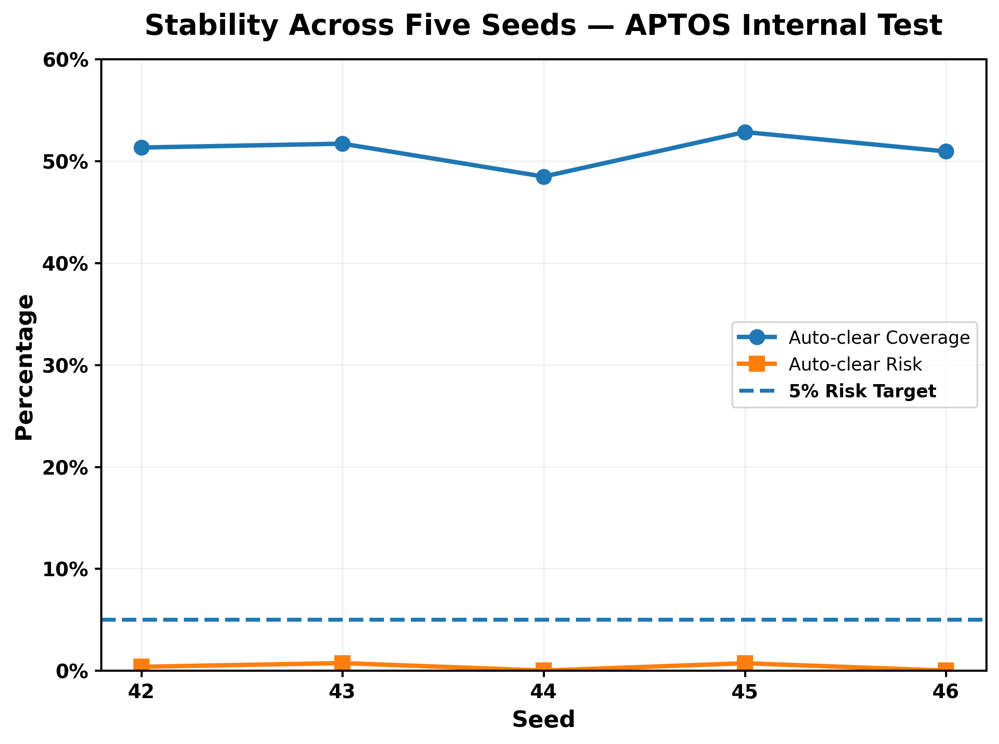


========== STABILITY SUMMARY ==========

Seed 42: Coverage = 51.33% | Risk = 0.37%
Seed 43: Coverage = 51.71% | Risk = 0.74%
Seed 44: Coverage = 48.48% | Risk = 0.00%
Seed 45: Coverage = 52.85% | Risk = 0.72%
Seed 46: Coverage = 50.95% | Risk = 0.00%

Mean Coverage = 51.06% ± 1.61%
Mean Risk = 0.37% ± 0.36%

DISPLAY ONLY - NO FILE SAVED.


In [ ]:
# ============================================================
# APTOS STABILITY ACROSS 5 SEEDS
# DISPLAY ONLY - NOTHING SAVED
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.special import expit
from matplotlib.ticker import PercentFormatter


# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_DR")

PRED_PATH = PROJECT_DIR / "aptos_retfound_raw_predictions.csv"
TEMP_PATH = PROJECT_DIR / "aptos_retfound_temperature_scaling.json"
LTT_PATH = PROJECT_DIR / "aptos_retfound_ltt_risk_control.csv"

SEEDS = [42, 43, 44, 45, 46]
ALPHA = 0.05


# ============================================================
# LOAD
# ============================================================

pred = pd.read_csv(PRED_PATH)
ltt = pd.read_csv(LTT_PATH)

with open(TEMP_PATH, "r") as f:
    temp_data = json.load(f)


# ============================================================
# COMPUTE EACH SEED
# ============================================================

rows = []

for seed in SEEDS:

    test = pred[
        (pred["seed"] == seed) &
        (pred["split"] == "internal_test")
    ].copy()

    assert len(test) == 526

    y = test["binary_label"].to_numpy(dtype=int)
    logits = test["raw_logit"].to_numpy(dtype=float)

    # Frozen temperature
    T = float(
        temp_data["seeds"][str(seed)]["temperature"]
    )

    prob = expit(logits / T)

    # Frozen 5% LTT threshold
    policy = ltt[
        (ltt["seed"] == seed) &
        np.isclose(ltt["alpha"], ALPHA)
    ]

    assert len(policy) == 1

    threshold = float(
        policy.iloc[0]["selected_threshold"]
    )

    auto_clear = prob <= threshold

    n_clear = int(auto_clear.sum())

    errors = int(
        (
            auto_clear &
            (y == 1)
        ).sum()
    )

    coverage = n_clear / len(y)

    risk = (
        errors / n_clear
        if n_clear > 0
        else np.nan
    )

    rows.append({
        "Seed": seed,
        "Coverage": coverage,
        "Risk": risk
    })


results = pd.DataFrame(rows)


# ============================================================
# PLOT
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.labelweight": "bold",
    "axes.titleweight": "bold"
})

fig, ax = plt.subplots(
    figsize=(8, 6),
    dpi=300
)

# Coverage
ax.plot(
    results["Seed"],
    results["Coverage"],
    marker="o",
    markersize=8,
    linewidth=2.5,
    label="Auto-clear Coverage"
)

# Risk
ax.plot(
    results["Seed"],
    results["Risk"],
    marker="s",
    markersize=8,
    linewidth=2.5,
    label="Auto-clear Risk"
)

# 5% target
ax.axhline(
    ALPHA,
    linestyle="--",
    linewidth=2.2,
    label="5% Risk Target"
)


# ============================================================
# FORMAT
# ============================================================

ax.set_title(
    "Stability Across Five Seeds — APTOS Internal Test",
    fontsize=16,
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "Seed",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel(
    "Percentage",
    fontsize=13,
    fontweight="bold"
)

ax.set_xticks(SEEDS)

ax.set_ylim(
    0,
    0.60
)

ax.yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

ax.tick_params(
    axis="both",
    labelsize=11,
    width=1.2
)

for label in (
    ax.get_xticklabels()
    + ax.get_yticklabels()
):
    label.set_fontweight("bold")


# ============================================================
# LEGEND
# ============================================================

legend = ax.legend(
    loc="center right",
    fontsize=10,
    frameon=True
)

for text in legend.get_texts():
    text.set_fontweight("normal")

# Make target bold
legend.get_texts()[-1].set_fontweight("bold")


# ============================================================
# GRID / BORDER
# ============================================================

ax.grid(
    alpha=0.20,
    linewidth=0.8
)

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()


# ============================================================
# RESULT
# ============================================================

print("\n========== STABILITY SUMMARY ==========\n")

for _, row in results.iterrows():

    print(
        f"Seed {int(row['Seed'])}: "
        f"Coverage = {row['Coverage']*100:.2f}% | "
        f"Risk = {row['Risk']*100:.2f}%"
    )

print(
    f"\nMean Coverage = "
    f"{results['Coverage'].mean()*100:.2f}% ± "
    f"{results['Coverage'].std(ddof=1)*100:.2f}%"
)

print(
    f"Mean Risk = "
    f"{results['Risk'].mean()*100:.2f}% ± "
    f"{results['Risk'].std(ddof=1)*100:.2f}%"
)

print("\nDISPLAY ONLY - NO FILE SAVED.")

#**Recover Result**

In [4]:
# ============================================================
# DR RESEARCH — RECOVER GBLS / SR-GBLS EXPERIMENT RESULTS
# Experiments 11, 12, 13, 14, 15
# Existing Google Drive connection
# READ-ONLY
# ============================================================

import os
import pandas as pd
from pathlib import Path
from datetime import datetime

DRIVE = Path("/content/drive/MyDrive")

if not DRIVE.exists():
    raise RuntimeError(
        "Google Drive is not mounted at /content/drive/MyDrive"
    )

# Previously recorded experiment output filenames
TARGETS = {
    "Exp 11 — GBLS": [
        "gbls_exp11_morphology_features_v1.csv",
        "gbls_exp11_results.csv"
    ],

    "Exp 12 — SR-GBLS": [
        "sr_gbls_exp12_results.csv"
    ],

    "Exp 13 — Matched-Coverage Comparison": [
        "sr_gbls_exp13_fair_coverage.csv"
    ],

    "Exp 14 — Grade-2 Failure Analysis": [
        "sr_gbls_exp14_idrid_grade2_audit.csv"
    ],

    "Exp 15 — Risk-Coverage Feasibility": [
        "sr_gbls_5pct_oracle_feasibility.csv"
    ]
}

KEYWORDS = [
    "gbls",
    "lesion",
    "morphology",
    "grade2",
    "grade_2",
    "fair_coverage",
    "feasibility",
    "oracle",
    "exp11",
    "exp12",
    "exp13",
    "exp14",
    "exp15"
]

EXTENSIONS = {
    ".csv", ".xlsx", ".json", ".parquet",
    ".ipynb", ".png", ".jpg", ".jpeg",
    ".pdf", ".svg", ".zip"
}

# ============================================================
# 1. SEARCH GOOGLE DRIVE
# ============================================================

print("=" * 70)
print("SEARCHING EXISTING GOOGLE DRIVE")
print("=" * 70)

found = []

for folder, subfolders, filenames in os.walk(DRIVE):

    for filename in filenames:

        path = Path(folder) / filename

        if path.suffix.lower() not in EXTENSIONS:
            continue

        name = filename.lower()

        if any(word in name for word in KEYWORDS):
            found.append(path)

found = sorted(set(found), key=lambda p: str(p).lower())

print(f"\nRelevant files found: {len(found)}")

for i, path in enumerate(found, 1):

    stat = path.stat()

    print(f"\n{i}. {path.name}")
    print("   Path:", path)
    print("   Size:", round(stat.st_size / 1024, 2), "KB")
    print(
        "   Modified:",
        datetime.fromtimestamp(stat.st_mtime)
    )

# ============================================================
# 2. CHECK EXPECTED OUTPUTS
# ============================================================

print("\n" + "=" * 70)
print("EXPERIMENT RECOVERY STATUS")
print("=" * 70)

records = []

for experiment, expected_files in TARGETS.items():

    print(f"\n{experiment}")

    for expected in expected_files:

        matches = [
            p for p in found
            if p.name.lower() == expected.lower()
        ]

        status = "FOUND" if matches else "NOT FOUND"

        print(f"  [{status}] {expected}")

        records.append({
            "experiment": experiment,
            "expected_file": expected,
            "status": status,
            "matches": len(matches),
            "paths": " | ".join(map(str, matches))
        })

status_df = pd.DataFrame(records)

# ============================================================
# 3. EXTRACT EXISTING NUMERICAL RESULTS
# ============================================================

print("\n" + "=" * 70)
print("RECOVERED EXPERIMENT OUTPUTS")
print("=" * 70)

for path in found:

    if path.suffix.lower() != ".csv":
        continue

    print("\n" + "-" * 70)
    print("FILE:", path.name)
    print("-" * 70)

    try:
        df = pd.read_csv(path)

        print("Rows:", len(df))
        print("Columns:", len(df.columns))
        print("\nColumn names:")
        print(df.columns.tolist())

        # Print small result tables completely.
        # Avoid flooding output with image-level feature records.

        if len(df) <= 100:
            print("\nRESULTS:")
            print(df.to_string(index=False))

        else:
            print("\nFIRST 10 ROWS:")
            print(df.head(10).to_string(index=False))

            print(
                "\nLarge file detected. "
                "Full data remains unchanged in Drive."
            )

    except Exception as e:
        print("Could not read CSV:", str(e))

# ============================================================
# 4. IDENTIFY EXISTING FIGURES
# ============================================================

print("\n" + "=" * 70)
print("EXISTING EXPERIMENT FIGURES")
print("=" * 70)

image_extensions = {".png", ".jpg", ".jpeg", ".svg"}

figures = [
    p for p in found
    if p.suffix.lower() in image_extensions
]

if figures:

    for path in figures:
        print(path)

else:
    print("No matching experiment figures found.")

# ============================================================
# 5. FINAL RECOVERY SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL RECOVERY SUMMARY")
print("=" * 70)

print(status_df[
    ["experiment", "expected_file", "status"]
].to_string(index=False))

print("\nExpected outputs found:",
      int((status_df["status"] == "FOUND").sum()))

print("Expected outputs missing:",
      int((status_df["status"] == "NOT FOUND").sum()))

print("\nOther matching files:", len(found))

print("\nSEARCH COMPLETED")
print("No files were modified.")

SEARCHING EXISTING GOOGLE DRIVE

Relevant files found: 8

1. Lesion Aware Kits23.ipynb
   Path: /content/drive/MyDrive/Colab Notebooks/Lesion Aware Kits23.ipynb
   Size: 1349.96 KB
   Modified: 2026-03-15 22:55:46

2. gbls_exp11_morphology_features_v1.csv
   Path: /content/drive/MyDrive/thesis_DR/gbls_exp11_morphology_features_v1.csv
   Size: 2726.22 KB
   Modified: 2026-11-07 09:57:50

3. gbls_exp11_results.csv
   Path: /content/drive/MyDrive/thesis_DR/gbls_exp11_results.csv
   Size: 22.08 KB
   Modified: 2026-11-07 09:57:52

4. lvan_lesion_scores.csv
   Path: /content/drive/MyDrive/thesis_DR/lvan_lesion_scores.csv
   Size: 242.61 KB
   Modified: 2026-11-07 08:13:49

5. sr_gbls_5pct_oracle_feasibility.csv
   Path: /content/drive/MyDrive/thesis_DR/sr_gbls_5pct_oracle_feasibility.csv
   Size: 1.05 KB
   Modified: 2026-11-07 10:50:56

6. sr_gbls_exp12_results.csv
   Path: /content/drive/MyDrive/thesis_DR/sr_gbls_exp12_results.csv
   Size: 11.96 KB
   Modified: 2026-11-07 10:10:42

7. sr_

In [5]:
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/thesis_DR")

exp11 = pd.read_csv(ROOT / "gbls_exp11_results.csv")
exp12 = pd.read_csv(ROOT / "sr_gbls_exp12_results.csv")
exp13 = pd.read_csv(ROOT / "sr_gbls_exp13_fair_coverage.csv")
exp15 = pd.read_csv(ROOT / "sr_gbls_5pct_oracle_feasibility.csv")

# --------------------------------------------------------
# 1. SOURCE-SELECTED THRESHOLDS: ALL METHODS
# --------------------------------------------------------

base = exp11[exp11["analysis"] == "source_LTT"].copy()
sr = exp12[exp12["analysis"] == "source_LTT"].copy()

combined = pd.concat([base, sr], ignore_index=True)

summary = (
    combined
    .groupby(["dataset", "method"])
    .agg(
        seeds=("seed", "nunique"),
        coverage_mean=("coverage_pct", "mean"),
        coverage_sd=("coverage_pct", "std"),
        risk_mean=("risk_pct", "mean"),
        risk_sd=("risk_pct", "std"),
        grade2_miss_mean=("grade2_miss_pct", "mean")
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("TABLE 1: SOURCE-SELECTED SCREENING RESULTS")
print("=" * 75)
print(summary.round(3).to_string(index=False))

# --------------------------------------------------------
# 2. MATCHED-COVERAGE COMPARISON
# --------------------------------------------------------

fair = (
    exp13[
        exp13["target_coverage_pct"].isin([20, 30, 35, 40])
    ]
    .groupby(["dataset", "target_coverage_pct", "method"])
    .agg(
        seeds=("seed", "nunique"),
        actual_coverage_mean=("actual_coverage_pct", "mean"),
        risk_mean=("risk_pct", "mean"),
        risk_sd=("risk_pct", "std"),
        grade2_miss_mean=("grade2_miss_pct", "mean")
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("TABLE 2: MATCHED-COVERAGE COMPARISON")
print("=" * 75)
print(fair.round(3).to_string(index=False))

# --------------------------------------------------------
# 3. CHECK WHETHER COMPARISON CUTOFFS ARE DEPLOYABLE
# --------------------------------------------------------

print("\n" + "=" * 75)
print("MATCHED-COVERAGE VALIDITY CHECK")
print("=" * 75)

print("Cutoff deployability:")
print(exp13["cutoff_is_deployable"].value_counts(dropna=False))

print("\nBoundary tie splitting:")
print(exp13["boundary_tie_split"].value_counts(dropna=False))

# --------------------------------------------------------
# 4. RETROSPECTIVE 5% FEASIBILITY
# --------------------------------------------------------

feasibility = (
    exp15.groupby("dataset")
    .agg(
        seeds=("seed", "nunique"),
        source_coverage_mean=("source_LTT_coverage_pct", "mean"),
        source_risk_mean=("source_LTT_risk_pct", "mean"),
        oracle_coverage_mean=("oracle_max_coverage_pct", "mean"),
        oracle_coverage_sd=("oracle_max_coverage_pct", "std"),
        oracle_risk_mean=("oracle_risk_pct", "mean")
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("TABLE 3: RETROSPECTIVE 5% FEASIBILITY")
print("=" * 75)
print(feasibility.round(3).to_string(index=False))

print("\nRESULT SUMMARY COMPLETE")


TABLE 1: SOURCE-SELECTED SCREENING RESULTS
   dataset                        method  seeds  coverage_mean  coverage_sd  risk_mean  risk_sd  grade2_miss_mean
     APTOS               GBLS_morphology      5         54.297        3.050      2.966    1.107             4.044
     APTOS GBLS_morphology_plus_RETFound      5         56.312        2.862      2.416    2.167             4.908
     APTOS                 LVAN_combined      5         51.483        1.959      2.034    1.161             1.878
     APTOS                   Lesion_only      5         53.346        1.628      2.842    0.504             3.177
     APTOS                 RETFound_only      5         55.932        2.165      2.132    1.444             4.475
     APTOS                       SR_GBLS      5         54.525        1.541      2.499    0.558             3.176
     IDRiD               GBLS_morphology      5         42.012        4.214     17.842    3.543            19.515
     IDRiD GBLS_morphology_plus_RETFound    

#**Retrospective Matched-Coverage Risk–Coverage Comparison of Lesion-Only, GBLS, and SR-GBLS**

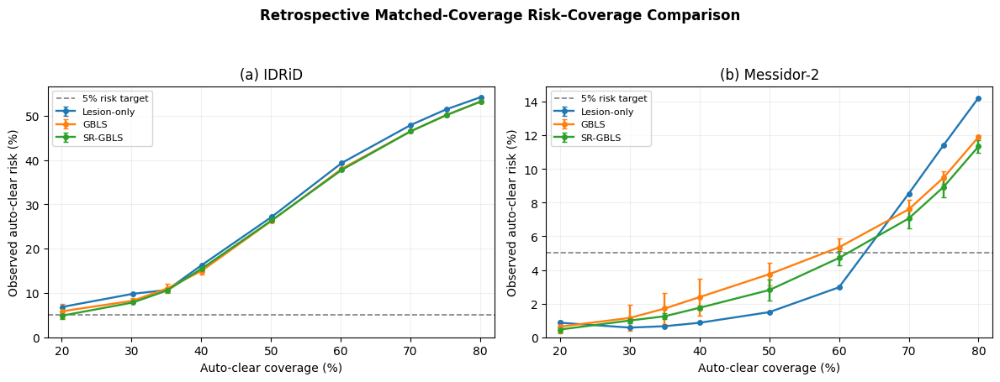

PNG: /content/drive/MyDrive/thesis_DR/figures/Fig5_Morphology_Matched_Coverage.png
PDF: /content/drive/MyDrive/thesis_DR/figures/Fig5_Morphology_Matched_Coverage.pdf
Comparison records: 270
Deployable cutoffs: 0
Boundary tie splits: 25


In [6]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Original Experiment 13 results
root = Path("/content/drive/MyDrive/thesis_DR")
source = root / "sr_gbls_exp13_fair_coverage.csv"

df = pd.read_csv(source)

methods = {
    "Lesion_only": "Lesion-only",
    "GBLS_morphology": "GBLS",
    "SR_GBLS": "SR-GBLS"
}

datasets = ["IDRiD", "Messidor-2"]

required = {
    "dataset", "seed", "method", "target_coverage_pct",
    "actual_coverage_pct", "risk_pct",
    "boundary_tie_split", "cutoff_is_deployable"
}
assert required.issubset(df.columns), "Required columns missing"

# Check that these are retrospective, non-deployable comparisons
deployable = (
    df["cutoff_is_deployable"]
    .astype(str).str.lower().eq("true")
)
assert not deployable.any(), (
    "Deployable cutoffs found. Recheck the analysis."
)

summary = (
    df[df["dataset"].isin(datasets) &
       df["method"].isin(methods)]
    .groupby(["dataset", "method", "target_coverage_pct"])
    .agg(
        coverage=("actual_coverage_pct", "mean"),
        mean_risk=("risk_pct", "mean"),
        sd_risk=("risk_pct", "std"),
        n_seeds=("seed", "nunique")
    )
    .reset_index()
)

assert (summary["n_seeds"] == 5).all(), (
    "One or more comparison points lack five seeds."
)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

for ax, dataset, panel in zip(
    axes, datasets, ["(a)", "(b)"]
):
    for method, label in methods.items():
        d = summary[
            (summary["dataset"] == dataset) &
            (summary["method"] == method)
        ].sort_values("coverage")

        ax.errorbar(
            d["coverage"],
            d["mean_risk"],
            yerr=d["sd_risk"],
            marker="o",
            markersize=4,
            linewidth=1.7,
            capsize=2.5,
            label=label
        )

    ax.axhline(
        5,
        linestyle="--",
        linewidth=1.2,
        color="gray",
        label="5% risk target"
    )

    ax.set_title(f"{panel} {dataset}")
    ax.set_xlabel("Auto-clear coverage (%)")
    ax.set_ylabel("Observed auto-clear risk (%)")
    ax.set_xlim(18, 82)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

fig.suptitle(
    "Retrospective Matched-Coverage Risk–Coverage Comparison",
    fontsize=12,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.93])

# Save publication-resolution files
output_dir = root / "figures"
output_dir.mkdir(parents=True, exist_ok=True)

png_path = output_dir / "Fig5_Morphology_Matched_Coverage.png"
pdf_path = output_dir / "Fig5_Morphology_Matched_Coverage.pdf"

fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")

plt.show()
plt.close(fig)

print("PNG:", png_path)
print("PDF:", pdf_path)

print("Comparison records:", len(df))
print("Deployable cutoffs:", int(deployable.sum()))
print(
    "Boundary tie splits:",
    int(
        df["boundary_tie_split"]
        .astype(str).str.lower().eq("true").sum()
    )
)
